# Explorer 03 - Formats and reissues

**Purpose.** Explore the format mix by year and settle on a definition of reissue.

**Feeds main report section:** 5.2 RQ2 - Format mix and the vinyl boom

**Modules used:** `vinyl.formats`, `vinyl.viz`

**Tables read:** `release_formats`, `releases`, `masters`, `release_genres`

This is a working notebook. It can be messy; anything that goes into the report is re-run from `main.ipynb` through the same functions in `vinyl/`.

In [1]:
# Make the `vinyl` package importable from the explorers/ folder.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "explorers":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

from pyspark.sql import functions as F
from vinyl import config, ingest

spark = ingest.get_spark(app_name="vinyl-03-formats")
from vinyl import formats, viz

In [2]:
snapshot = config.MAIN_SNAPSHOT  # "2026"
release_formats = ingest.read_table(spark, snapshot, "release_formats")
releases = ingest.read_table(spark, snapshot, "releases")
masters = ingest.read_table(spark, snapshot, "masters")
release_genres = ingest.read_table(spark, snapshot, "release_genres")

## 1. What formats and descriptions exist?

In [3]:
release_formats.groupBy("format_name").agg(F.countDistinct("release_id").alias("n")).orderBy(F.desc("n")).show(30, truncate=False)

+-----------------+-------+
|format_name      |n      |
+-----------------+-------+
|File             |1686928|
|Vinyl            |947149 |
|CD               |739064 |
|Cassette         |253332 |
|CDr              |171296 |
|All Media        |34340  |
|Box Set          |23367  |
|Lathe Cut        |21225  |
|DVD              |19651  |
|Blu-ray          |7515   |
|SACD             |5173   |
|Flexi-disc       |3383   |
|Memory Stick     |3087   |
|DVDr             |2503   |
|Floppy Disk      |1302   |
|Minidisc         |1285   |
|VHS              |831    |
|Reel-To-Reel     |667    |
|Blu-ray-R        |526    |
|8-Track Cartridge|492    |
|Acetate          |370    |
|Hybrid           |289    |
|Microcassette    |173    |
|Ultra HD Blu-ray |157    |
|DAT              |65     |
|Cylinder         |25     |
|DCC              |22     |
|Zip Disk         |20     |
|Shellac          |12     |
|Super VHS        |9      |
+-----------------+-------+
only showing top 30 rows


In [4]:
release_formats.select(F.explode("descriptions").alias("description")).groupBy("description").count().orderBy(F.desc("count")).show(40, truncate=False)

+------------------+-------+
|description       |count  |
+------------------+-------+
|Album             |1499908|
|MP3               |866122 |
|LP                |660458 |
|Limited Edition   |644793 |
|Single            |527133 |
|EP                |481855 |
|Stereo            |465575 |
|FLAC              |362892 |
|Reissue           |351639 |
|WAV               |297077 |
|Compilation       |259431 |
|AAC               |211513 |
|12"               |194477 |
|Numbered          |159507 |
|45 RPM            |154167 |
|Remastered        |136858 |
|7"                |123445 |
|33 ⅓ RPM          |100257 |
|Unofficial Release|86923  |
|Promo             |69639  |
|Test Pressing     |56064  |
|Repress           |42566  |
|AIFF              |41550  |
|Single Sided      |41464  |
|Mini-Album        |36640  |
|Deluxe Edition    |32992  |
|Special Edition   |30038  |
|White Label       |25370  |
|ALAC              |24557  |
|Mixed             |21729  |
|10"               |20748  |
|Mixtape      

## 2. Format shares by year

In [5]:
format_shares = formats.format_shares_by_year(release_formats).toPandas()
main_formats = formats.main_formats(format_shares, min_share=0.01)
print("Main formats (>= 1% of releases in at least one full year, largest mean share first):")
print(main_formats)

Main formats (>= 1% of releases in at least one full year, largest mean share first):
['File', 'Vinyl', 'CD', 'Cassette', 'CDr', 'All Media', 'DVD']


Text(2026.4, 0.544177890816275, '2026 partial\n(Jan-Sep)')

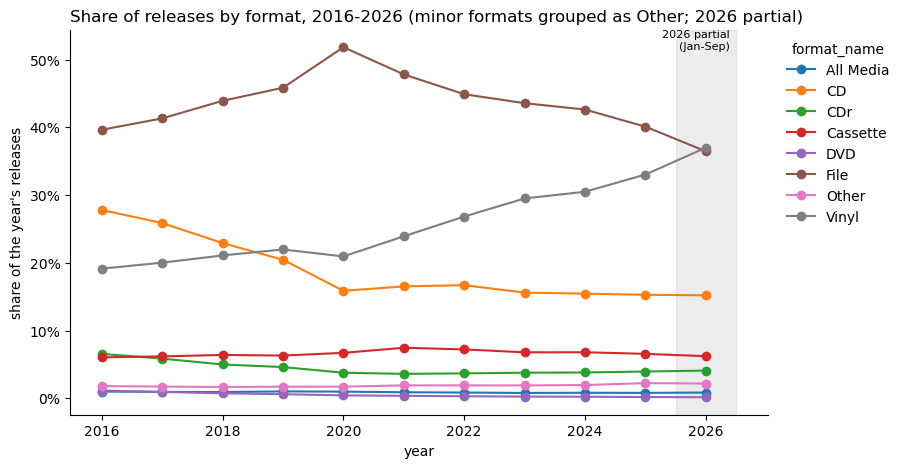

In [6]:
grouped_shares = formats.format_shares_by_year(
    formats.group_minor_formats(release_formats, main_formats)
).toPandas()
ax = viz.plot_lines(
    grouped_shares, "year", "share", "format_name",
    title="Share of releases by format, 2016-2026 (minor formats grouped as Other; 2026 partial)",
    ylabel="share of the year's releases", percent=True,
)
ax.axvspan(config.LAST_FULL_YEAR + 0.5, config.YEAR_MAX + 0.5, color="grey", alpha=0.15)
ax.text(config.YEAR_MAX + 0.4, ax.get_ylim()[1], "2026 partial\n(Jan-Sep)", ha="right", va="top", fontsize=8)

## 3. Reissue definitions

Compare the tag-based flag (`is_reissue`) with the master-based flag (`is_reissue_master`) before picking one.

In [7]:
flagged = formats.add_master_reissue_flag(release_formats, releases, masters, min_gap_years=1)
flagged.groupBy("is_reissue", "is_reissue_master").agg(F.countDistinct("release_id").alias("n")).show()

+----------+-----------------+-------+
|is_reissue|is_reissue_master|      n|
+----------+-----------------+-------+
|      true|            false|  28763|
|      true|             NULL|  32210|
|      true|             true| 344035|
|     false|            false|1230921|
|     false|             true| 214206|
|     false|             NULL|2000188|
+----------+-----------------+-------+



In [8]:
vinyl = flagged.where(F.col("format_name") == "Vinyl")
print(f"End year for comparisons: {config.LAST_FULL_YEAR} (2026 is partial)")
for flag in ["is_reissue", "is_reissue_master", "is_reissue_any"]:
    print(flag)
    formats.reissue_share(vinyl, by=["year"], flag_col=flag).orderBy("year").show()

End year for comparisons: 2025 (2026 is partial)
is_reissue


+----+----------+----------+-----+-------------------+
|year|n_releases|n_reissues|n_new|      reissue_share|
+----+----------+----------+-----+-------------------+
|2016|     73730|     14973|58757|0.20307880103078801|
|2017|     78156|     15723|62433|0.20117457392906496|
|2018|     83660|     17177|66483| 0.2053191489361702|
|2019|     86550|     17106|69444| 0.1976429809358752|
|2020|     87042|     18317|68725|0.21043863881804187|
|2021|     93575|     22423|71152| 0.2396259684744857|
|2022|     96821|     24605|72216| 0.2541287530597701|
|2023|    102399|     26235|76164|0.25620367386400256|
|2024|     95178|     21483|73695| 0.2257139254869823|
|2025|     92779|     20187|72592| 0.2175815647937572|
|2026|     57259|     12626|44633|0.22050681988857646|
+----+----------+----------+-----+-------------------+

is_reissue_master


+----+----------+----------+-----+-------------------+
|year|n_releases|n_reissues|n_new|      reissue_share|
+----+----------+----------+-----+-------------------+
|2016|     73730|     19803|53927|0.26858809168588094|
|2017|     78156|     20724|57432|  0.265161983724858|
|2018|     83660|     22575|61085| 0.2698422185034664|
|2019|     86550|     23108|63442| 0.2669901790872328|
|2020|     87042|     24314|62728|0.27933641230670253|
|2021|     93575|     31180|62395| 0.3332086561581619|
|2022|     96821|     35319|61502|0.36478656489811095|
|2023|    102399|     37315|65084| 0.3644078555454643|
|2024|     95178|     29985|65193| 0.3150412910546555|
|2025|     92779|     27940|64839|    0.3011457334095|
|2026|     57259|     17660|39599| 0.3084231299882988|
+----+----------+----------+-----+-------------------+

is_reissue_any


+----+----------+----------+-----+-------------------+
|year|n_releases|n_reissues|n_new|      reissue_share|
+----+----------+----------+-----+-------------------+
|2016|     73730|     21353|52377| 0.2896107418961074|
|2017|     78156|     22380|55776|0.28635037617073544|
|2018|     83660|     24387|59273|0.29150131484580444|
|2019|     86550|     24948|61602|0.28824956672443675|
|2020|     87042|     26330|60712|0.30249764481514674|
|2021|     93575|     33193|60382| 0.3547208121827411|
|2022|     96821|     37280|59541| 0.3850404354427242|
|2023|    102399|     39310|63089|0.38389046768034846|
|2024|     95178|     31971|63207|0.33590745760574925|
|2025|     92779|     29936|62843| 0.3226592224533569|
|2026|     57259|     18942|38317| 0.3308126233430552|
+----+----------+----------+-----+-------------------+



### Share of vinyl growth explained by reissues

`(reissues_end - reissues_start) / (releases_end - releases_start)` for vinyl, from `config.YEAR_MIN` to `config.LAST_FULL_YEAR`, for each flag. Null means vinyl releases did not grow.

In [9]:
from functools import reduce

by_flag = [
    formats.reissue_share(vinyl, by=["year"], flag_col=flag).withColumn("flag", F.lit(flag))
    for flag in ["is_reissue", "is_reissue_master", "is_reissue_any"]
]
growth = formats.growth_explained_by_reissues(
    reduce(lambda a, b: a.unionByName(b), by_flag), config.YEAR_MIN, config.LAST_FULL_YEAR
)
growth.orderBy("flag").show(truncate=False)

+-----------------+--------------+------------+--------------+------------+------------------+
|flag             |releases_start|releases_end|reissues_start|reissues_end|growth_explained  |
+-----------------+--------------+------------+--------------+------------+------------------+
|is_reissue       |73730         |92779       |14973         |20187       |0.2737151556512153|
|is_reissue_any   |73730         |92779       |21353         |29936       |0.450574833324584 |
|is_reissue_master|73730         |92779       |19803         |27940       |0.4271615307890178|
+-----------------+--------------+------------+--------------+------------+------------------+



## 4. Reissue share by genre

In [10]:
by_genre = formats.reissue_share(
    flagged.join(release_genres.select("release_id", "genre"), "release_id"),
    by=["year", "format_name", "genre"],
    flag_col="is_reissue_any",
)
by_genre.where(F.col("format_name") == "Vinyl").orderBy("genre", "year").show(40)

+----+-----------+----------------+----------+----------+-----+-------------------+
|year|format_name|           genre|n_releases|n_reissues|n_new|      reissue_share|
+----+-----------+----------------+----------+----------+-----+-------------------+
|2016|      Vinyl|           Blues|      1786|       726| 1060|  0.406494960806271|
|2017|      Vinyl|           Blues|      1854|       721| 1133| 0.3888888888888889|
|2018|      Vinyl|           Blues|      1913|       738| 1175| 0.3857814950339781|
|2019|      Vinyl|           Blues|      1929|       696| 1233| 0.3608087091757387|
|2020|      Vinyl|           Blues|      1670|       599| 1071| 0.3586826347305389|
|2021|      Vinyl|           Blues|      1749|       629| 1120| 0.3596340766152087|
|2022|      Vinyl|           Blues|      1728|       701| 1027| 0.4056712962962963|
|2023|      Vinyl|           Blues|      1849|       737| 1112| 0.3985938345051379|
|2024|      Vinyl|           Blues|      1730|       585| 1145|0.33815028901

## 5. How old is the music being reissued?

Age is `year - master_year`, for releases that have a master. A master dated after the release is left out and counted below.

Distinct releases with master_year later than the release year (left out): {'Vinyl': 3749, 'CD': 2571}


/home2/bsdsba2028/jsandiego/bdcc-lab2-wt/T06/lab2/vinyl/viz.py:116: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = data.pivot_table(index=x, columns=series, values=y, aggfunc="sum").fillna(0)


/home2/bsdsba2028/jsandiego/bdcc-lab2-wt/T06/lab2/vinyl/viz.py:116: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = data.pivot_table(index=x, columns=series, values=y, aggfunc="sum").fillna(0)


,Vinyl,CD
year,,
2016,18,24
2017,19,24
2018,18,25
2019,17,23
2020,18,23
2021,16,24
2022,15,24
2023,17,25
2024,20,26


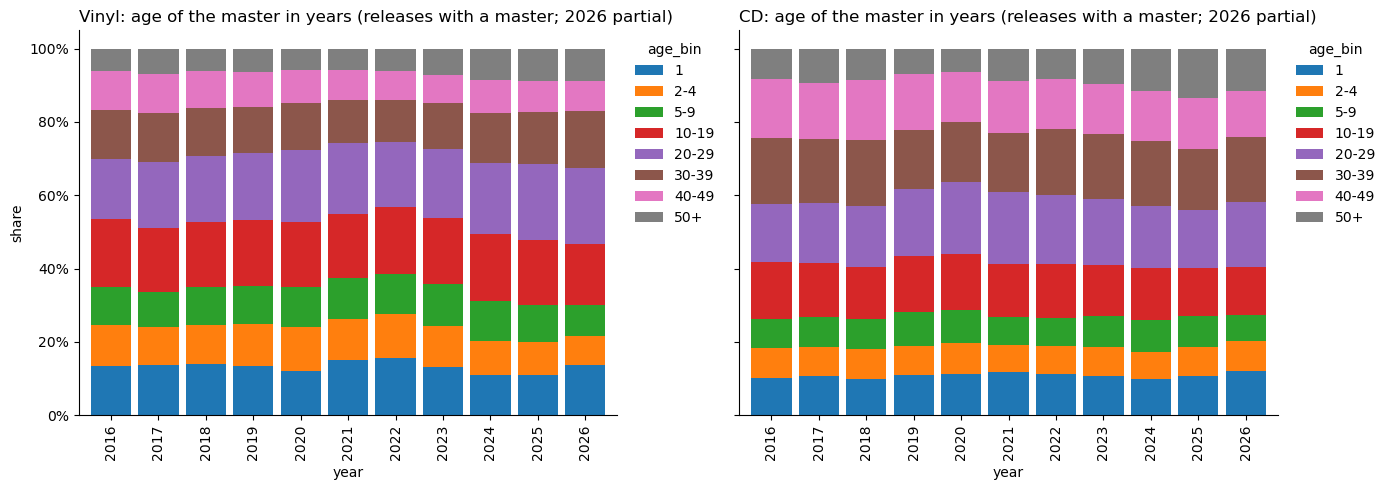

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

age = {fmt: formats.reissue_age_distribution(flagged, fmt).toPandas() for fmt in ["Vinyl", "CD"]}
print("Distinct releases with master_year later than the release year (left out):",
      {fmt: formats.count_master_after_release(flagged, fmt) for fmt in age})

labels = formats.age_bin_labels()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (fmt, pdf) in zip(axes, age.items()):
    pdf = pdf.assign(age_bin=pd.Categorical(pdf["age_bin"], categories=labels, ordered=True))
    viz.plot_stacked_share(
        pdf, "year", "n_releases", "age_bin",
        title=f"{fmt}: age of the master in years (releases with a master; 2026 partial)", ax=ax,
    )
fig.tight_layout()
pd.DataFrame({fmt: pdf.groupby("year")["median_age"].first() for fmt, pdf in age.items()})

## 6. Pressing plants

Check the spelling of the role in `entity_type_name` before using it.

In [12]:
release_companies = ingest.read_table(spark, snapshot, "release_companies")
(release_companies.where(F.col("entity_type_name").rlike("(?i)press|manufactur"))
    .groupBy("entity_type", "entity_type_name").agg(F.countDistinct("release_id").alias("n"))
    .orderBy(F.desc("n")).show(truncate=False))
role = "Pressed By"

+-----------+----------------+------+
|entity_type|entity_type_name|n     |
+-----------+----------------+------+
|17         |Pressed By      |220455|
|10         |Manufactured By |171416|
|38         |Manufactured For|10902 |
+-----------+----------------+------+



,rank,company_id,company_name,total_full_years
36,1,430654,GZ Media,60766
2,2,313190,Optimal Media GmbH,20556
45,3,56025,MPO,16574
0,4,267164,Record Industry,12161
15,5,271440,Schallplattenfabrik Pallas GmbH,6031
5,6,523699,Precision Record Pressing,3704
7,7,178173,Zenith Records (2),3261
25,8,321797,Gotta Groove Records,3113
1,9,66254,Record Technology Incorporated,2677
34,10,833505,Memphis Record Pressing,2635


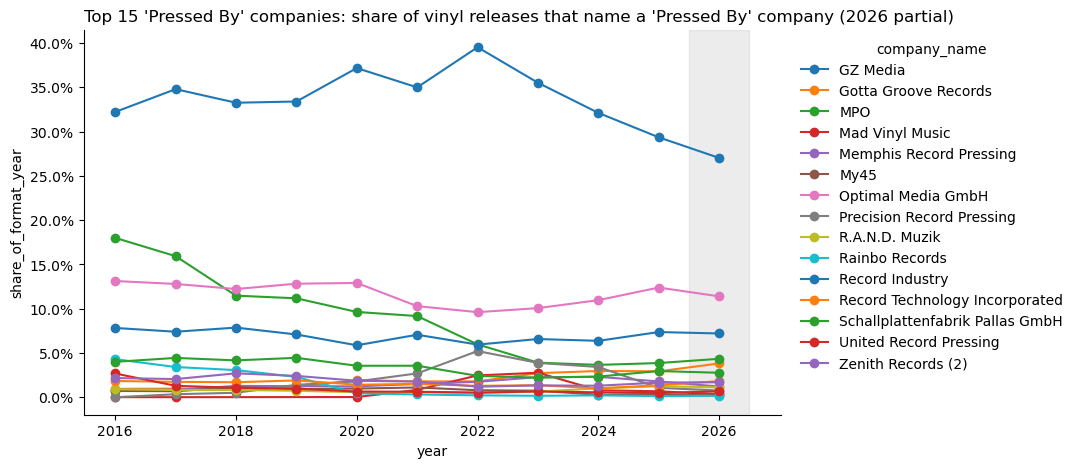

In [13]:
plants = formats.top_pressing_plants(release_companies, release_formats, "Vinyl", role, top_n=15).toPandas()
display(plants.drop_duplicates("company_id").sort_values("rank")[["rank", "company_id", "company_name", "total_full_years"]])
ax = viz.plot_lines(
    plants, "year", "share_of_format_year", "company_name",
    title=f"Top 15 '{role}' companies: share of vinyl releases that name a '{role}' company (2026 partial)",
    percent=True,
)
ax.axvspan(config.LAST_FULL_YEAR + 0.5, config.YEAR_MAX + 0.5, color="grey", alpha=0.15)

In [14]:
# Coverage: share of vinyl releases per year that name any pressing plant at all.
formats.pressing_plant_coverage(release_companies, release_formats, "Vinyl", role).orderBy("year").show(truncate=False)

+----+--------+-----------+-------------------+
|year|n_format|n_with_role|coverage           |
+----+--------+-----------+-------------------+
|2016|73730   |16866      |0.2287535602875356 |
|2017|78156   |17795      |0.22768565433236093|
|2018|83660   |18266      |0.21833612240019126|
|2019|86550   |18900      |0.21837088388214904|
|2020|87042   |19025      |0.2185726430918407 |
|2021|93575   |18330      |0.1958856532193428 |
|2022|96821   |19974      |0.20629822042738663|
|2023|102399  |18915      |0.18471860076758562|
|2024|95178   |15911      |0.1671709848914665 |
|2025|92779   |12084      |0.13024499078455254|
|2026|57259   |6468       |0.11296040797079936|
+----+--------+-----------+-------------------+



## 7. Digital ("File") releases

In [15]:
formats.format_coverage(release_formats, releases, "File").orderBy("year").show(truncate=False)

+----+--------+----------+-------------------+-----------+------------------+-------------------------------------------------------------------------------------------------------------------------+
|year|n_format|n_releases|share              |n_with_desc|desc_coverage     |top_descriptions                                                                                                         |
+----+--------+----------+-------------------+-----------+------------------+-------------------------------------------------------------------------------------------------------------------------+
|2016|152750  |385281    |0.396463879609947  |152705     |0.9997054009819967|[{MP3, 86994}, {Album, 30590}, {FLAC, 29845}, {Single, 29828}, {EP, 29744}, {WAV, 23249}, {AAC, 13946}, {Stereo, 8476}]  |
|2017|161321  |390355    |0.41326741043409204|161321     |1.0               |[{MP3, 92465}, {Single, 34252}, {FLAC, 30832}, {EP, 30648}, {Album, 29482}, {WAV, 25129}, {AAC, 15904}, {Stereo, 9357}]  |


**Reading rule.** If the File share jumps or collapses in step with catalogue policy rather than smoothly, File is not comparable across years. Read `share`, `desc_coverage` and `top_descriptions` together for such breaks.

## Decisions to carry into `main.ipynb`

Filled in from the full-data runs in `executed/`. Each line should end up as a sentence in the report's methodology or limitations.

- [x] Reissue definition: `is_reissue_any` (a Reissue, Repress or Remastered tag, or a master at least 1 year older than the release), with the tag-only and master-only definitions reported next to it. The two flags miss different releases: 214,206 releases are reissues by master only and 28,763 by tag only (section 3).
- [x] Formats shown: File, Vinyl, CD, Cassette, CDr, All Media and DVD, the formats with at least 1% of releases in at least one full year (`formats.main_formats(min_share=0.01)`); all others are grouped as Other (1.7-2.2% of releases per year).
- [x] Share of vinyl growth explained by reissues, 2016 to 2025: 45.1% with `is_reissue_any` (vinyl releases 73,730 to 92,779, reissues 21,353 to 29,936); 27.4% with tags only and 42.7% with masters only.